In [ ]:
# Exploratory data analysis
# EDA means examining your data using statistics, tables, and graphs before drawing conclusions.

In [1]:
# Install the required Python libraries
!pip install pandas numpy matplotlib seaborn scipy sqlalchemy pymysql

In [ ]:
"""
Library	and Purpose
pandas - Read SQL data and manipulate tables
numpy -	Numerical calculations
matplotlib - Create charts
seaborn - Create statistical charts
scipy - Statistical analysis
sqlalchemy - Connect Python to MySQL
pymysql - MySQL database driver

"""

In [2]:
# Import the libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sqlalchemy import create_engine
from urllib.parse import quote_plus

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [ ]:
"""
Explanation:
- import pandas as pd: allows you to use commands such as pd.read_sql() and pd.DataFrame().
- import numpy as np: gives you numerical tools and missing-value handling.
- matplotlib.pyplot as plt: creates graphs.
- seaborn as sns: creates histograms, boxplots, heatmaps, and other statistical graphs.
- from scipy import stats: provides statistical tools, including Q-Q plots.
- create_engine: establishes a connection to MySQL.
- quote_plus: safely encodes special characters in your database password when constructing the connection URL.
- warnings.filterwarnings("ignore"): hides warnings. During debugging, it is better to remove this line so warnings remain visible.
- sns.set_theme(...): makes the charts easier to read.
- pd.set_option(...): adjusts how tables and numbers appear in notebook output.
"""

In [3]:
# Connect Jupyter Notebook to your MySQL database
import pandas as pd
from sqlalchemy import create_engine, URL

connection_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password="Arul@nitha08",
    host="localhost",
    port=3306,
    database="olist_db"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("MySQL connected successfully!")

MySQL connected successfully!


In [ ]:
# Feature Engineering

In [9]:
# 7.1 Bring the base data from SQL

orders = pd.read_sql("""
    SELECT o.order_id, o.customer_id, c.customer_unique_id, c.customer_state, c.customer_city,
           o.order_status, o.order_purchase_timestamp, o.order_approved_at,
           o.order_delivered_carrier_date, o.order_delivered_customer_date,
           o.order_estimated_delivery_date
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
""", engine)

date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

order_totals = pd.read_sql("""
    SELECT order_id,
           COUNT(*)                  AS item_count,
           COUNT(DISTINCT seller_id) AS seller_count,
           SUM(price)                AS items_value,
           SUM(freight_value)        AS freight_value,
           SUM(total_value)          AS order_value
    FROM order_items
    GROUP BY order_id
""", engine)

payments = pd.read_sql("""
    SELECT order_id,
           SUM(payment_value)        AS payment_value,
           MAX(payment_installments) AS max_installments,
           COUNT(*)                  AS payment_count
    FROM order_payments
    GROUP BY order_id
""", engine)

main_payment = pd.read_sql("""
    SELECT order_id, payment_type AS main_payment_type
    FROM order_payments
    WHERE payment_sequential = 1
""", engine)

reviews = pd.read_sql("""
    SELECT order_id, AVG(review_score) AS review_score
    FROM order_reviews
    GROUP BY order_id
""", engine)

print(orders.shape, order_totals.shape, payments.shape, main_payment.shape, reviews.shape)

(99441, 11) (98666, 6) (99437, 4) (99357, 2) (98669, 2)


In [10]:
# 7.2 Order-level features (total order value, delivery days, delivery delay)
# Total order value is order_value, which was summed in SQL above.
order_df = (orders
            .merge(order_totals, on="order_id", how="left")
            .merge(payments, on="order_id", how="left")
            .merge(main_payment, on="order_id", how="left")
            .merge(reviews, on="order_id", how="left"))

# Delivery days
order_df["delivery_days"] = (
    (order_df["order_delivered_customer_date"] - order_df["order_purchase_timestamp"])
    .dt.total_seconds() / 86400
)

# Delivery delay (positive = late)
order_df["delivery_delay_days"] = (
    (order_df["order_delivered_customer_date"] - order_df["order_estimated_delivery_date"])
    .dt.total_seconds() / 86400
)
order_df["is_late"] = np.where(order_df["delivery_delay_days"].isna(), np.nan,
                               (order_df["delivery_delay_days"] > 0).astype(float))

# Time features for trend analysis
order_df["purchase_month"] = order_df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
order_df["purchase_dow"]   = order_df["order_purchase_timestamp"].dt.day_name()
order_df["purchase_hour"]  = order_df["order_purchase_timestamp"].dt.hour

# Keep real sales only
orders_valid = order_df[~order_df["order_status"].isin(["canceled", "unavailable"])
                        & order_df["order_value"].notna()].copy()
delivered = orders_valid[orders_valid["delivery_days"].notna()].copy()

print("all orders:", len(order_df), "| valid sales orders:", len(orders_valid), "| delivered:", len(delivered))
orders_valid[["order_id", "order_value", "delivery_days", "delivery_delay_days", "is_late"]].head()

all orders: 99441 | valid sales orders: 98199 | delivered: 96470


,order_id,order_value,delivery_days,delivery_delay_days,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,7.614421,-8.011250,0.0
1,00018f77f2f0320c557190d7a144bdd3,259.83,16.216181,-2.330278,0.0
2,000229ec398224ef6ca0657da4fc703e,216.87,7.948437,-13.444954,0.0
3,00024acbcdf0a6daa1e931b038114c75,25.78,6.147269,-5.435660,0.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,25.114352,-15.303808,0.0


In [11]:
# 7.3 Customer features (order count, total spending, average order value, repeat indicator)
# Customers are grouped on customer_unique_id, because customer_id changes with every order.
customer_features = (orders_valid.groupby("customer_unique_id")
    .agg(customer_order_count=("order_id", "nunique"),
         customer_total_spend=("order_value", "sum"),
         first_order_date=("order_purchase_timestamp", "min"),
         last_order_date=("order_purchase_timestamp", "max"),
         customer_state=("customer_state", "first"))
    .reset_index())

customer_features["avg_order_value"]     = customer_features["customer_total_spend"] / customer_features["customer_order_count"]
customer_features["is_repeat_customer"]  = (customer_features["customer_order_count"] > 1).astype(int)

print("customers:", len(customer_features))
print("repeat customers: {:.2f}%".format(customer_features["is_repeat_customer"].mean() * 100))
customer_features.head()

customers: 94983
repeat customers: 3.04%


,customer_unique_id,customer_order_count,customer_total_spend,first_order_date,last_order_date,customer_state,avg_order_value,is_repeat_customer
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,2018-05-10 10:56:27,2018-05-10 10:56:27,SP,141.90,0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,2018-05-07 11:11:27,2018-05-07 11:11:27,SP,27.19,0
2,0000f46a3911fa3c0805444483337064,1,86.22,2017-03-10 21:05:03,2017-03-10 21:05:03,SC,86.22,0
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,2017-10-12 20:29:41,2017-10-12 20:29:41,PA,43.62,0
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,2017-11-14 19:45:42,2017-11-14 19:45:42,SP,196.89,0


In [12]:
# 7.4 Seller features (revenue, order count)
sellers = pd.read_sql("SELECT seller_id, seller_city, seller_state FROM sellers", engine)
items = pd.read_sql("""
    SELECT order_id, order_item_id, product_id, seller_id, price, freight_value, total_value
    FROM order_items
""", engine)

items_valid = items[items["order_id"].isin(orders_valid["order_id"])].copy()
items_valid = items_valid.merge(
    orders_valid[["order_id", "review_score", "delivery_delay_days"]], on="order_id", how="left")

seller_features = (items_valid.groupby("seller_id")
    .agg(seller_revenue=("price", "sum"),
         seller_order_count=("order_id", "nunique"),
         seller_items_sold=("order_id", "size"),
         seller_avg_item_price=("price", "mean"),
         seller_avg_review=("review_score", "mean"),
         seller_avg_delay_days=("delivery_delay_days", "mean"))
    .reset_index()
    .merge(sellers, on="seller_id", how="left"))

seller_features["seller_avg_order_value"] = seller_features["seller_revenue"] / seller_features["seller_order_count"]

print("sellers:", len(seller_features))
seller_features.sort_values("seller_revenue", ascending=False).head(10)

sellers: 3053


,seller_id,seller_revenue,seller_order_count,seller_items_sold,seller_avg_item_price,seller_avg_review,seller_avg_delay_days,seller_city,seller_state,seller_avg_order_value
849,4869f7a5dfa277a7dca6462dcf3b52b2,229237.63,1131,1155,198.474139,4.125545,-10.453161,guariba,SP,202.685791
1000,53243585a1d6dc2643021fd1853d8905,222776.05,358,410,543.356220,4.075980,-10.877354,lauro de freitas,BA,622.279469
873,4a3ca9315b744ce9f8e9374361493884,200326.12,1804,1985,100.919960,3.804592,-8.954641,ibitinga,SP,111.045521
2984,fa1c13f2614d7b5c4749cbc52fecda94,192842.13,584,585,329.644667,4.344234,-9.612764,sumare,SP,330.209127
1515,7c67e1448b00f6e969d365cea6b010ab,187923.89,982,1364,137.774113,3.345133,-10.832570,itaquaquecetuba,SP,191.368523
1540,7e93a43ef30c4f03f38b393420bc753a,172583.88,332,336,513.642500,4.238806,-11.485531,barueri,SP,519.830964
2611,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1314,1551,103.311779,4.067314,-10.527563,piracicaba,SP,121.945639
1485,7a67c85e85bb2ce8582c35f2203ad736,141715.54,1159,1170,121.124393,4.236865,-11.160569,sao paulo,SP,122.273978
191,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,915,1428,97.316912,3.846045,-10.388772,sao paulo,SP,151.878197
1799,955fee9216a65b617aa5c0531780ce60,135159.70,1286,1498,90.226769,4.052490,-9.626675,sao paulo,SP,105.100855


In [13]:
# 7.5 Attach customer features back to the order table
orders_valid = orders_valid.merge(
    customer_features[["customer_unique_id", "customer_order_count",
                       "customer_total_spend", "is_repeat_customer"]],
    on="customer_unique_id", how="left")
delivered = orders_valid[orders_valid["delivery_days"].notna()].copy()

orders_valid[["order_value", "freight_value", "item_count", "delivery_days",
              "delivery_delay_days", "customer_order_count",
              "customer_total_spend"]].describe().T

,count,mean,std,min,25%,50%,75%,max
order_value,98199.0,160.241215,219.111166,9.590000,61.960000,105.280000,176.730000,13664.080000
freight_value,98199.0,22.822292,21.645764,0.000000,13.860000,17.190000,24.050000,1794.960000
item_count,98199.0,1.141570,0.537556,1.000000,1.000000,1.000000,1.000000,21.000000
delivery_days,96470.0,12.558217,9.546156,0.533414,6.766204,10.217477,15.720182,209.628611
delivery_delay_days,96470.0,-11.178126,10.184354,-146.016123,-16.244065,-11.948102,-6.389815,188.975081
customer_order_count,98199.0,1.076844,0.383260,1.000000,1.000000,1.000000,1.000000,16.000000
customer_total_spend,98199.0,171.286611,233.902231,9.590000,64.090000,111.210000,189.080000,13664.080000


In [14]:
# 7.6 Optional: save the feature tables back to MySQL
# This creates two new tables and leaves the original tables untouched.
customer_features.to_sql("customer_features", engine, if_exists="replace", index=False, chunksize=5000)
seller_features.to_sql("seller_features", engine, if_exists="replace", index=False, chunksize=5000)
print("saved: customer_features, seller_features")

saved: customer_features, seller_features


In [ ]:
# Exploratory data analysis
# 8.0 Extra data from SQL: product categories

In [15]:
items_eda = pd.read_sql("""
    SELECT i.order_id, i.price, i.freight_value,
           p.product_weight_g,
           COALESCE(t.category_label, p.product_category_name, 'Unknown') AS category
    FROM order_items i
    JOIN products p ON i.product_id = p.product_id
    LEFT JOIN product_category_name_translation t
           ON p.product_category_name = t.product_category_name
""", engine)

items_eda = items_eda[items_eda["order_id"].isin(orders_valid["order_id"])].merge(
    orders_valid[["order_id", "customer_state"]], on="order_id", how="left")
print(items_eda.shape)
items_eda.head()

(112101, 6)


,order_id,price,freight_value,product_weight_g,category,customer_state
0,f30149f4a8882a08895b6a242aa0d612,101.65,18.59,300.0,Perfumery,RS
1,f5eda0ded77c1293b04c953138c8331d,129.90,13.93,1225.0,Auto,SP
2,0bf736fd0fd5169d60de3699fcbcf986,229.00,13.10,300.0,Bed Bath Table,SP
3,3aba44d8e554ab4bb8c09f6f78032ca8,58.90,19.60,550.0,Housewares,RS
4,6f0dfb5b5398b271cc6bbd9ee263530e,58.90,19.60,550.0,Housewares,RS


In [16]:
# 8.1 Univariate analysis
num_cols = ["order_value", "freight_value", "item_count", "delivery_days",
            "delivery_delay_days", "review_score", "max_installments"]
orders_valid[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
order_value,98199.0,160.241215,219.111166,9.590000,61.960000,105.280000,176.730000,13664.080000
freight_value,98199.0,22.822292,21.645764,0.000000,13.860000,17.190000,24.050000,1794.960000
item_count,98199.0,1.141570,0.537556,1.000000,1.000000,1.000000,1.000000,21.000000
delivery_days,96470.0,12.558217,9.546156,0.533414,6.766204,10.217477,15.720182,209.628611
delivery_delay_days,96470.0,-11.178126,10.184354,-146.016123,-16.244065,-11.948102,-6.389815,188.975081
review_score,97463.0,4.116383,1.321030,1.000000,4.000000,5.000000,5.000000,5.000000
max_installments,98198.0,2.931007,2.714541,0.000000,1.000000,2.000000,4.000000,24.000000


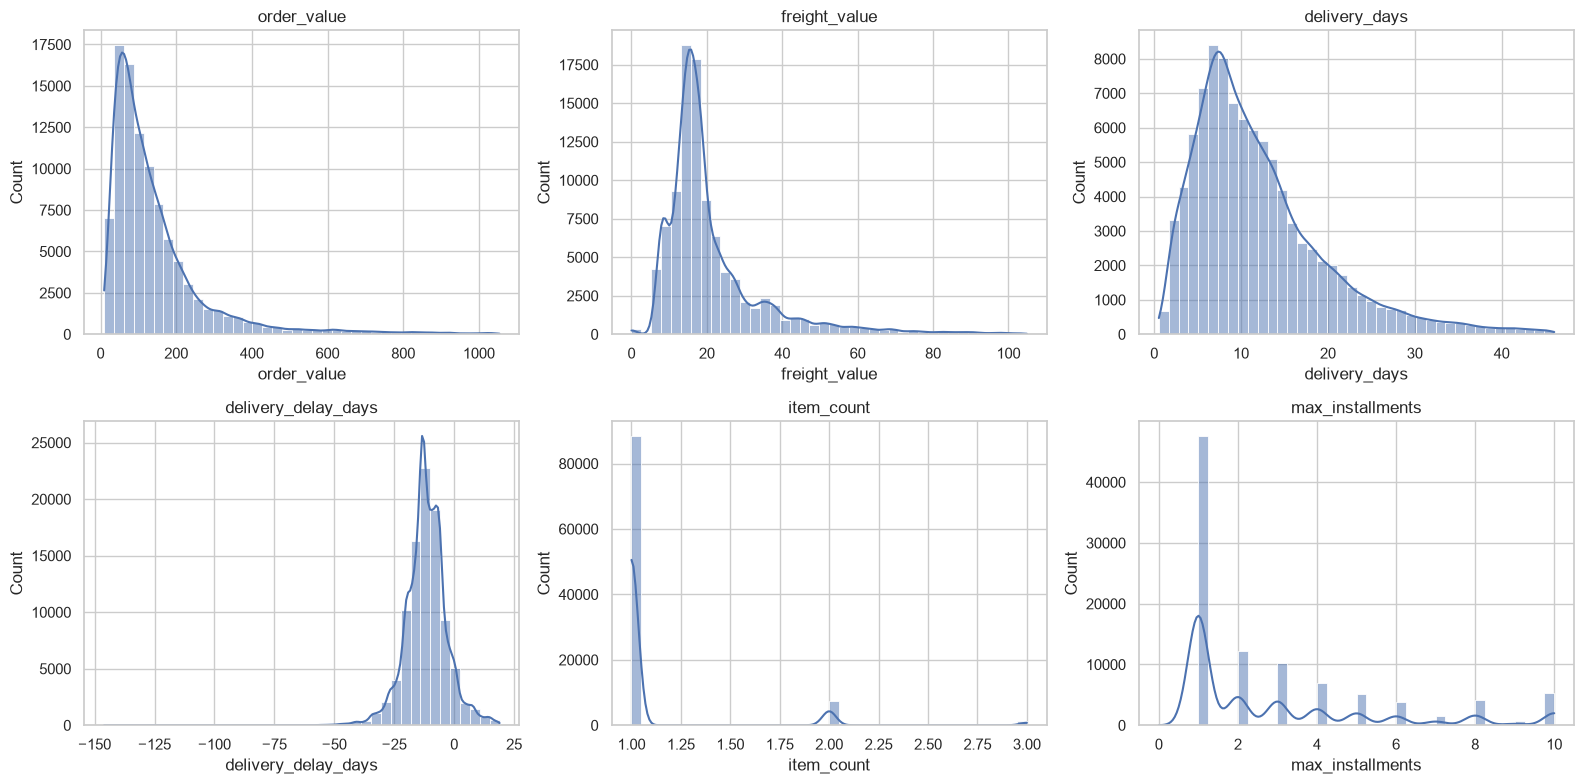

In [17]:
# Histograms (clipped at the 99th percentile)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ["order_value", "freight_value", "delivery_days",
                                  "delivery_delay_days", "item_count", "max_installments"]):
    s = orders_valid[col].dropna()
    s = s[s <= s.quantile(0.99)]
    sns.histplot(s, bins=40, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

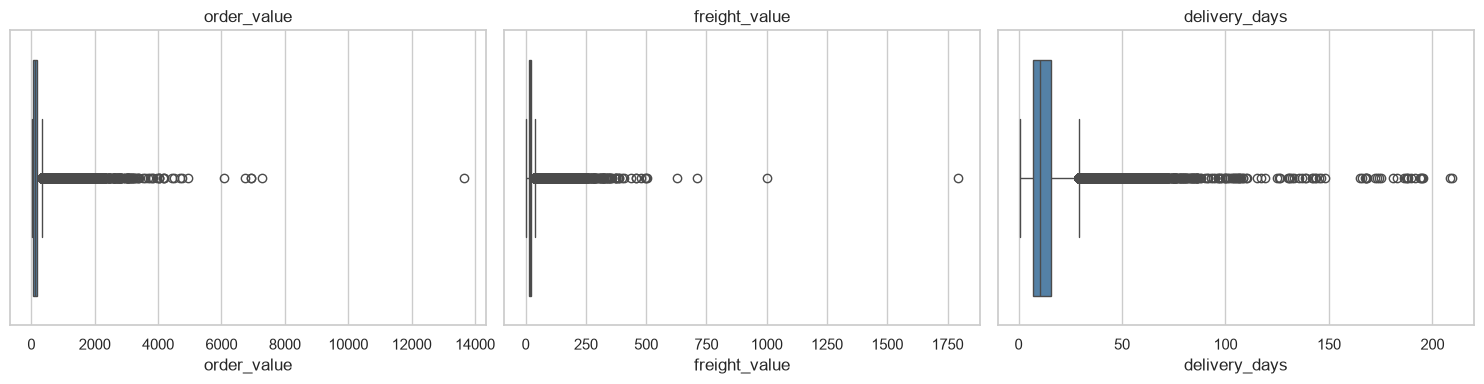

In [18]:
# Boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["order_value", "freight_value", "delivery_days"]):
    sns.boxplot(x=orders_valid[col], ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

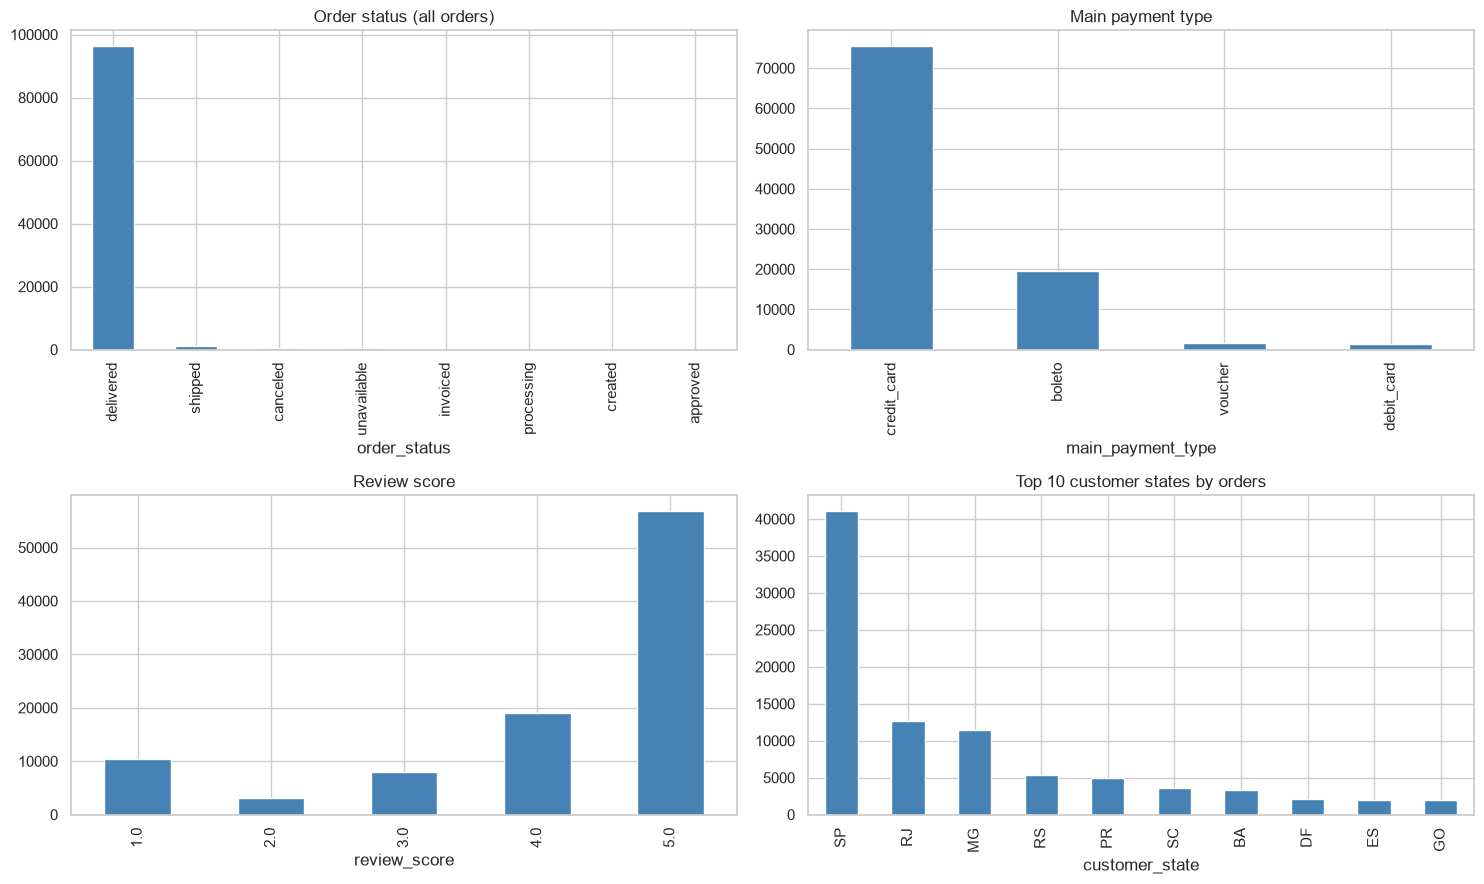

In [19]:
# Categorical variables
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

order_df["order_status"].value_counts().plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Order status (all orders)")

orders_valid["main_payment_type"].value_counts().plot(kind="bar", ax=axes[0, 1], color="steelblue")
axes[0, 1].set_title("Main payment type")

orders_valid["review_score"].round().value_counts().sort_index().plot(kind="bar", ax=axes[1, 0], color="steelblue")
axes[1, 0].set_title("Review score")

orders_valid["customer_state"].value_counts().head(10).plot(kind="bar", ax=axes[1, 1], color="steelblue")
axes[1, 1].set_title("Top 10 customer states by orders")

plt.tight_layout()
plt.show()

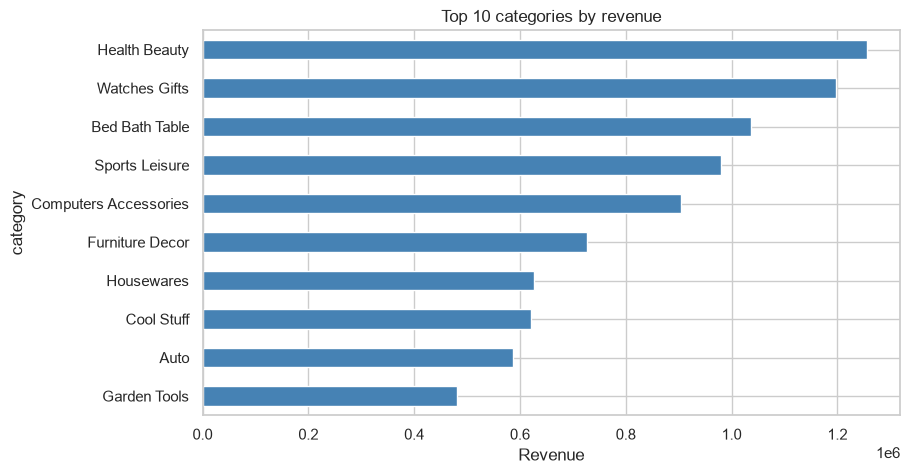

In [20]:
# Top 10 categories by revenue
top_cat = items_eda.groupby("category")["price"].sum().sort_values(ascending=False).head(10)
top_cat.sort_values().plot(kind="barh", figsize=(9, 5), color="steelblue")
plt.title("Top 10 categories by revenue")
plt.xlabel("Revenue")
plt.show()

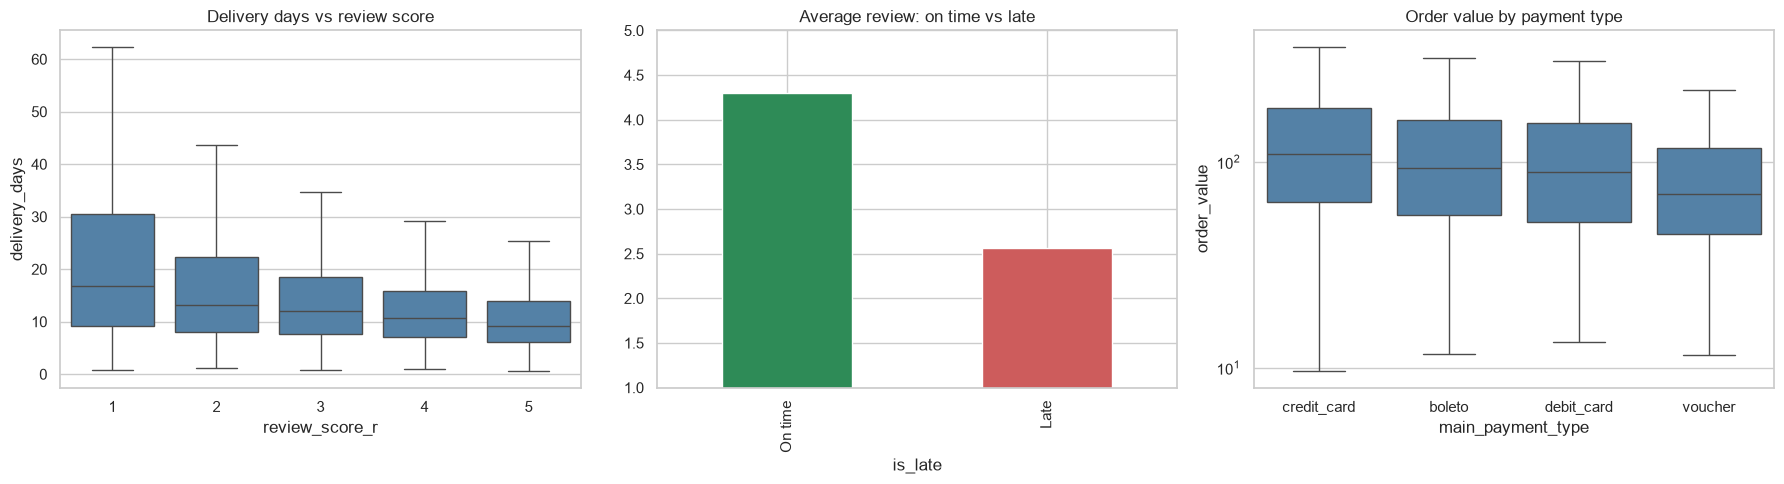

In [21]:
# 8.2 Bivariate analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

d = delivered.dropna(subset=["review_score"]).copy()
d["review_score_r"] = d["review_score"].round().astype(int)
sns.boxplot(data=d, x="review_score_r", y="delivery_days", showfliers=False, ax=axes[0], color="steelblue")
axes[0].set_title("Delivery days vs review score")

d.groupby("is_late")["review_score"].mean().rename({0.0: "On time", 1.0: "Late"}).plot(
    kind="bar", ax=axes[1], color=["seagreen", "indianred"])
axes[1].set_title("Average review: on time vs late")
axes[1].set_ylim(1, 5)

sns.boxplot(data=orders_valid, x="main_payment_type", y="order_value", showfliers=False, ax=axes[2], color="steelblue")
axes[2].set_yscale("log")
axes[2].set_title("Order value by payment type")
plt.tight_layout()
plt.show()

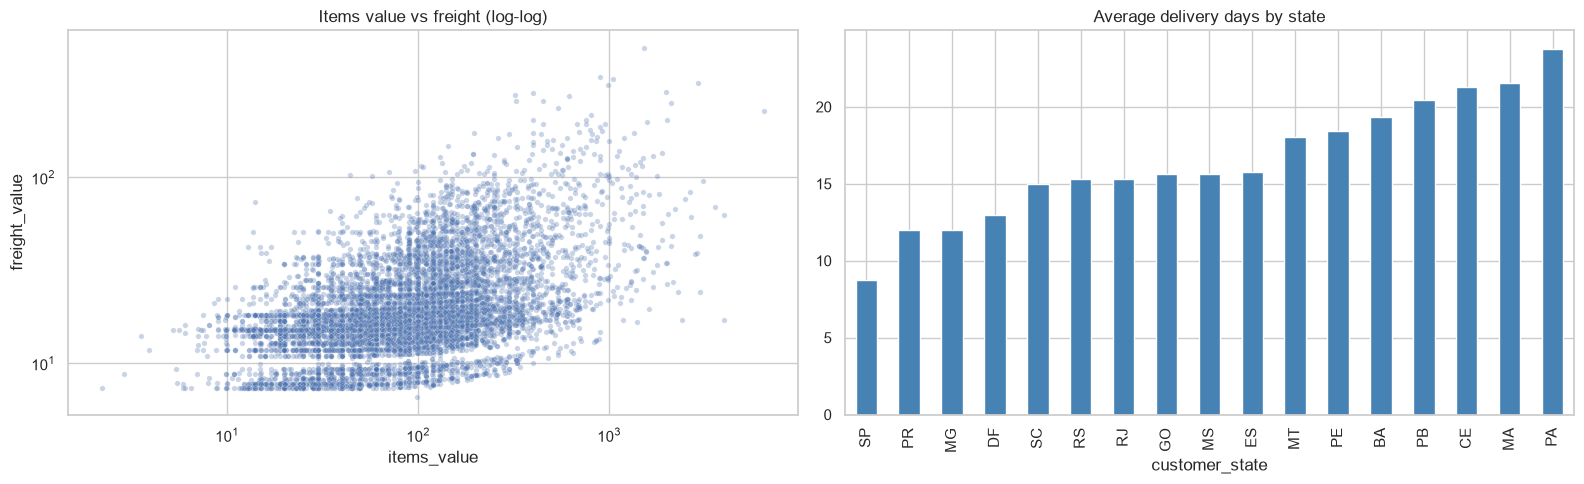

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

samp = orders_valid.sample(min(10000, len(orders_valid)), random_state=42)
sns.scatterplot(data=samp, x="items_value", y="freight_value", alpha=0.3, s=15, ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Items value vs freight (log-log)")

st = delivered.groupby("customer_state").agg(avg_days=("delivery_days", "mean"), n=("order_id", "count"))
st = st[st["n"] >= 500].sort_values("avg_days")
st["avg_days"].plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Average delivery days by state")
plt.tight_layout()
plt.show()

In [23]:
# Repeat vs one-time customers
cmp = orders_valid.groupby("is_repeat_customer").agg(
    avg_order_value=("order_value", "mean"),
    avg_freight=("freight_value", "mean"),
    avg_review=("review_score", "mean"),
    orders=("order_id", "count"))
cmp.index = cmp.index.map({0: "One-time", 1: "Repeat"})
cmp

,avg_order_value,avg_freight,avg_review,orders
is_repeat_customer,,,,
One-time,161.193883,22.817272,4.112474,92096
Repeat,145.865183,22.898047,4.175488,6103


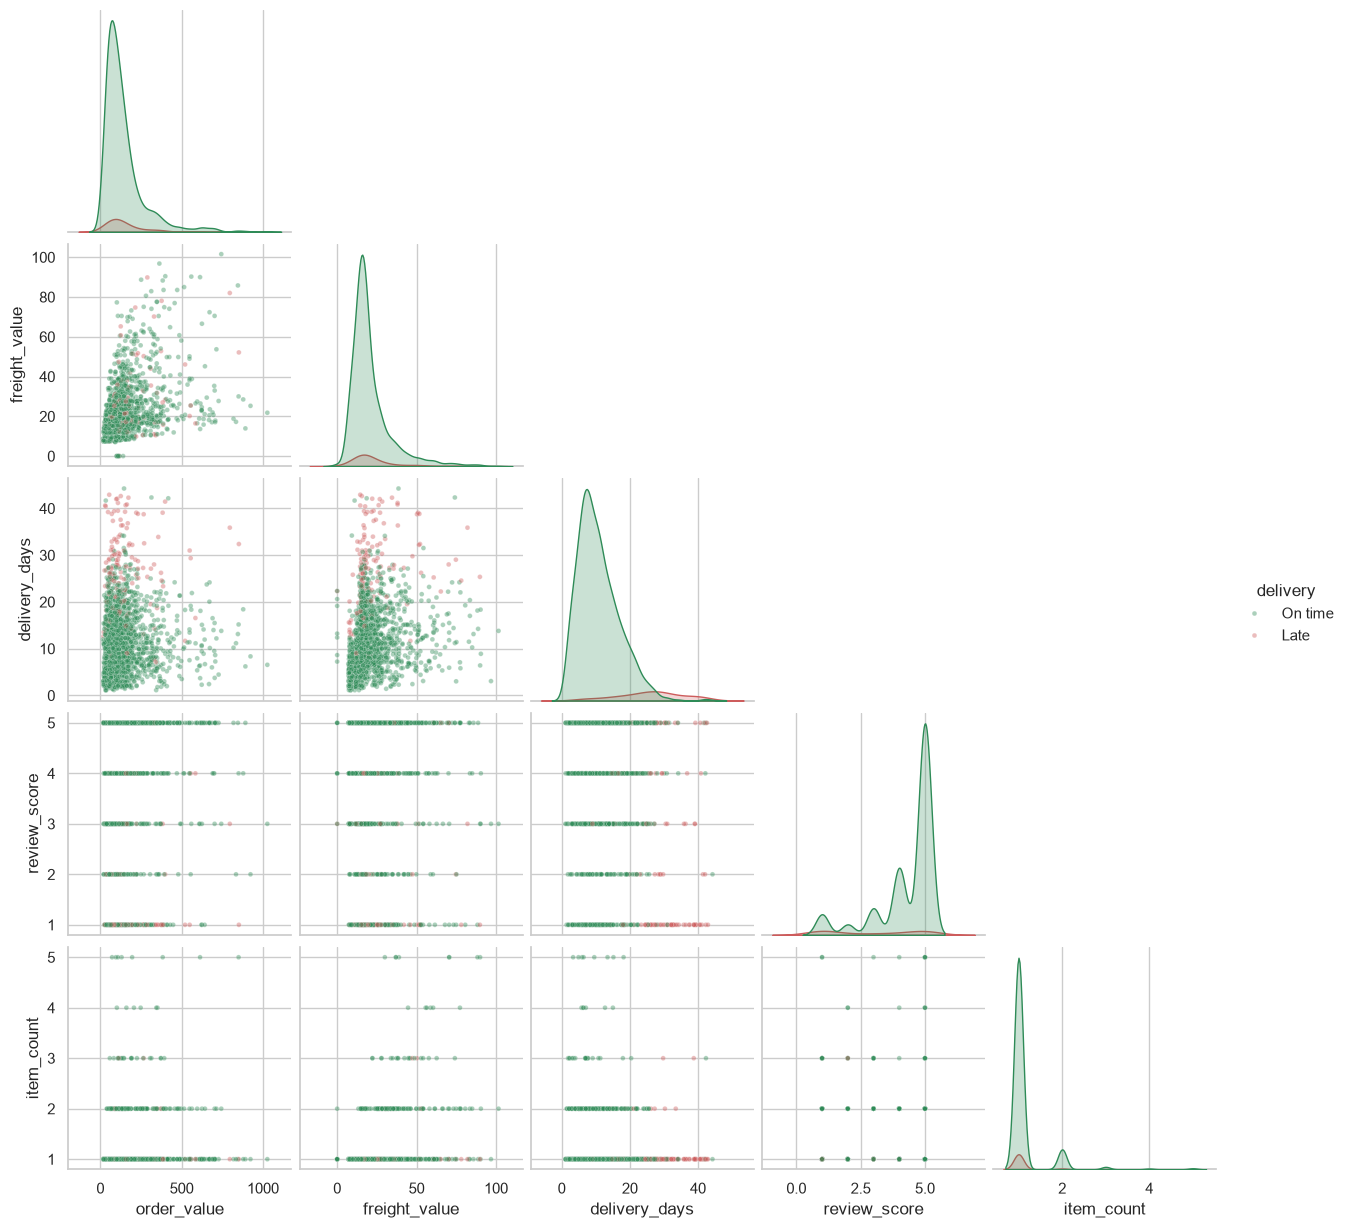

In [24]:
# 8.3 Multivariate analysis
# Pairplot coloured by late delivery
cols = ["order_value", "freight_value", "delivery_days", "review_score", "item_count"]
pp = delivered[cols + ["is_late"]].dropna()
pp = pp[(pp["order_value"] < pp["order_value"].quantile(0.99)) &
        (pp["freight_value"] < pp["freight_value"].quantile(0.99)) &
        (pp["delivery_days"] < pp["delivery_days"].quantile(0.99))]
pp = pp.sample(min(2000, len(pp)), random_state=42)
pp["delivery"] = pp["is_late"].map({0.0: "On time", 1.0: "Late"})
sns.pairplot(pp.drop(columns="is_late"), hue="delivery", corner=True,
             plot_kws={"alpha": 0.4, "s": 12}, palette={"On time": "seagreen", "Late": "indianred"})
plt.show()

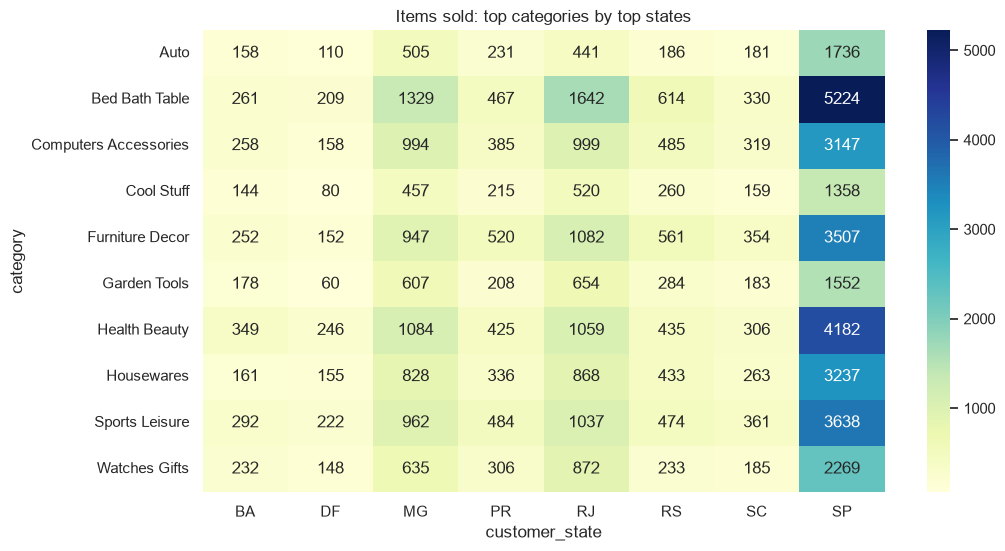

In [25]:
# Top categories x top states
top_categories = items_eda.groupby("category")["price"].sum().nlargest(10).index
top_states = orders_valid["customer_state"].value_counts().head(8).index
sub = items_eda[items_eda["category"].isin(top_categories) & items_eda["customer_state"].isin(top_states)]
ct = pd.crosstab(sub["category"], sub["customer_state"])

plt.figure(figsize=(11, 6))
sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Items sold: top categories by top states")
plt.show()

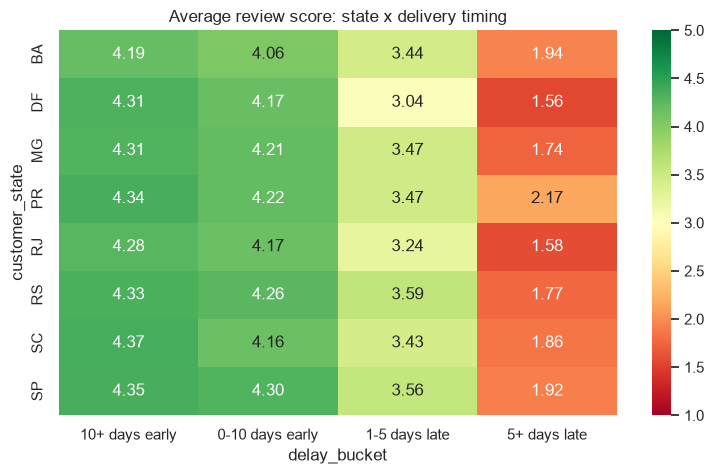

In [26]:
# Review score by delivery timing and state
d2 = delivered.dropna(subset=["review_score"]).copy()
d2["delay_bucket"] = pd.cut(d2["delivery_delay_days"], bins=[-100, -10, 0, 5, 100],
                            labels=["10+ days early", "0-10 days early", "1-5 days late", "5+ days late"])
pv = (d2[d2["customer_state"].isin(top_states)]
      .pivot_table(index="customer_state", columns="delay_bucket", values="review_score", aggfunc="mean"))

plt.figure(figsize=(9, 5))
sns.heatmap(pv, annot=True, fmt=".2f", cmap="RdYlGn", vmin=1, vmax=5)
plt.title("Average review score: state x delivery timing")
plt.show()

In [ ]:
# 8.4 Trend analysis

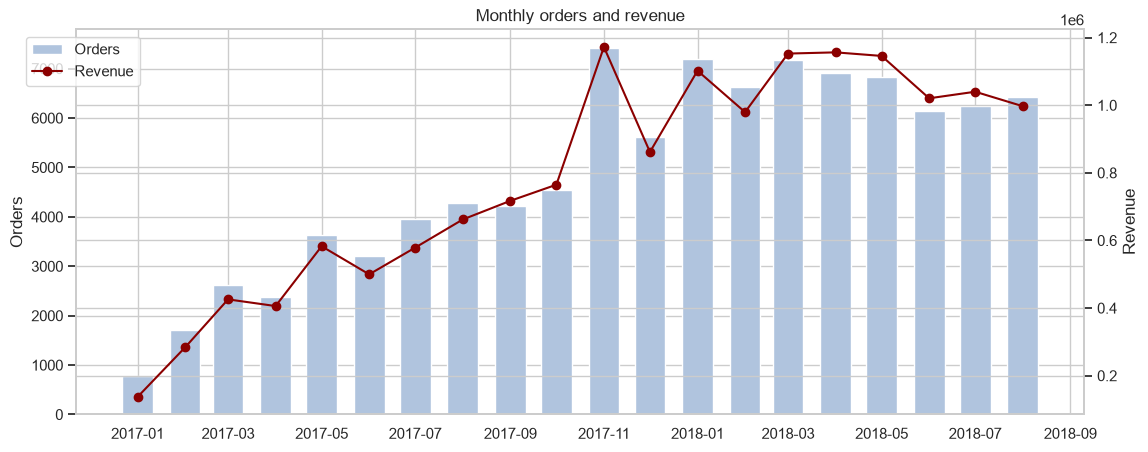

,orders,revenue,avg_order_value,avg_delivery_days,late_pct,avg_review
purchase_month,,,,,,
2017-01-01,787,136943.46,174.006938,12.647044,3.066667,4.092664
2017-02-01,1718,283561.69,165.053370,13.168825,3.206292,4.103286
2017-03-01,2617,425617.96,162.635827,12.951184,5.577376,4.131640
2017-04-01,2377,405848.61,170.739844,14.917913,7.859314,4.066525
2017-05-01,3640,582710.83,160.085393,11.322363,3.610719,4.176650
2017-06-01,3205,499652.24,155.897735,12.011573,3.859649,4.176360
2017-07-01,3946,578753.73,146.668457,11.592732,3.434917,4.226541
2017-08-01,4272,661903.52,154.939963,11.147125,3.315049,4.268333
2017-09-01,4227,717102.72,169.648148,11.851007,5.204819,4.221745


In [27]:
# The first and last months of the data are partial, so the window is trimmed. Change START and END if your data differs.
START, END = "2017-01-01", "2018-08-01"
m = orders_valid[(orders_valid["purchase_month"] >= START) & (orders_valid["purchase_month"] <= END)]

monthly = m.groupby("purchase_month").agg(
    orders=("order_id", "nunique"),
    revenue=("order_value", "sum"),
    avg_order_value=("order_value", "mean"),
    avg_delivery_days=("delivery_days", "mean"),
    late_pct=("is_late", lambda s: s.mean() * 100),
    avg_review=("review_score", "mean"))

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(monthly.index, monthly["orders"], width=20, color="lightsteelblue", label="Orders")
ax1.set_ylabel("Orders")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["revenue"], color="darkred", marker="o", label="Revenue")
ax2.set_ylabel("Revenue")
plt.title("Monthly orders and revenue")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
plt.show()

monthly

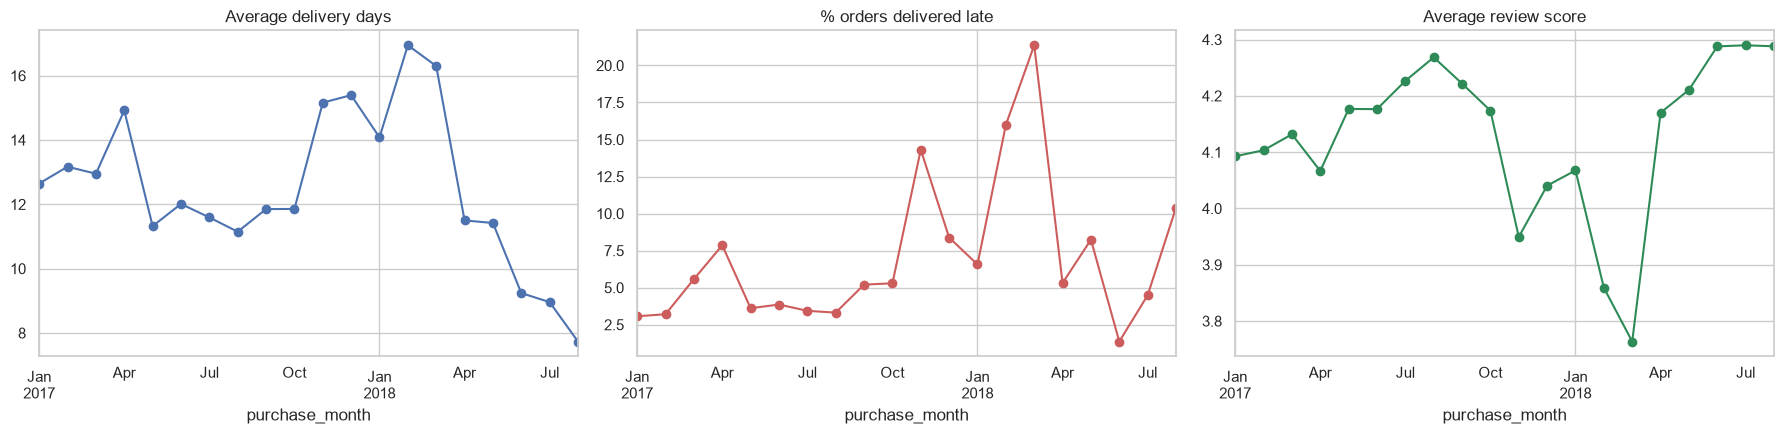

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
monthly["avg_delivery_days"].plot(ax=axes[0], marker="o"); axes[0].set_title("Average delivery days")
monthly["late_pct"].plot(ax=axes[1], marker="o", color="indianred"); axes[1].set_title("% orders delivered late")
monthly["avg_review"].plot(ax=axes[2], marker="o", color="seagreen"); axes[2].set_title("Average review score")
plt.tight_layout()
plt.show()

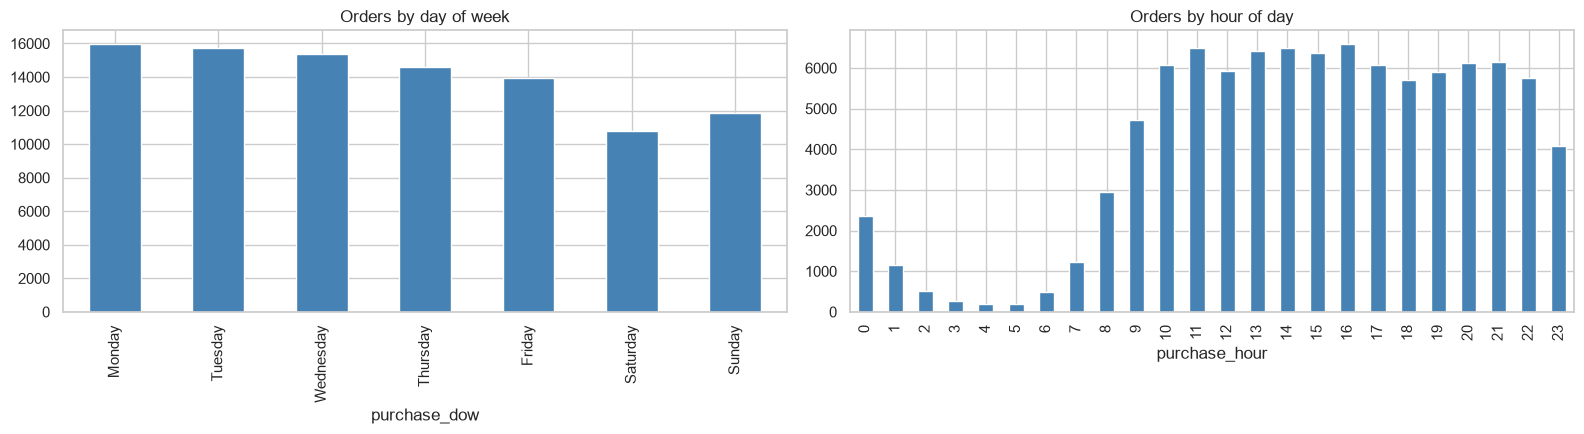

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
orders_valid["purchase_dow"].value_counts().reindex(dow_order).plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Orders by day of week")

orders_valid["purchase_hour"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Orders by hour of day")
plt.tight_layout()
plt.show()

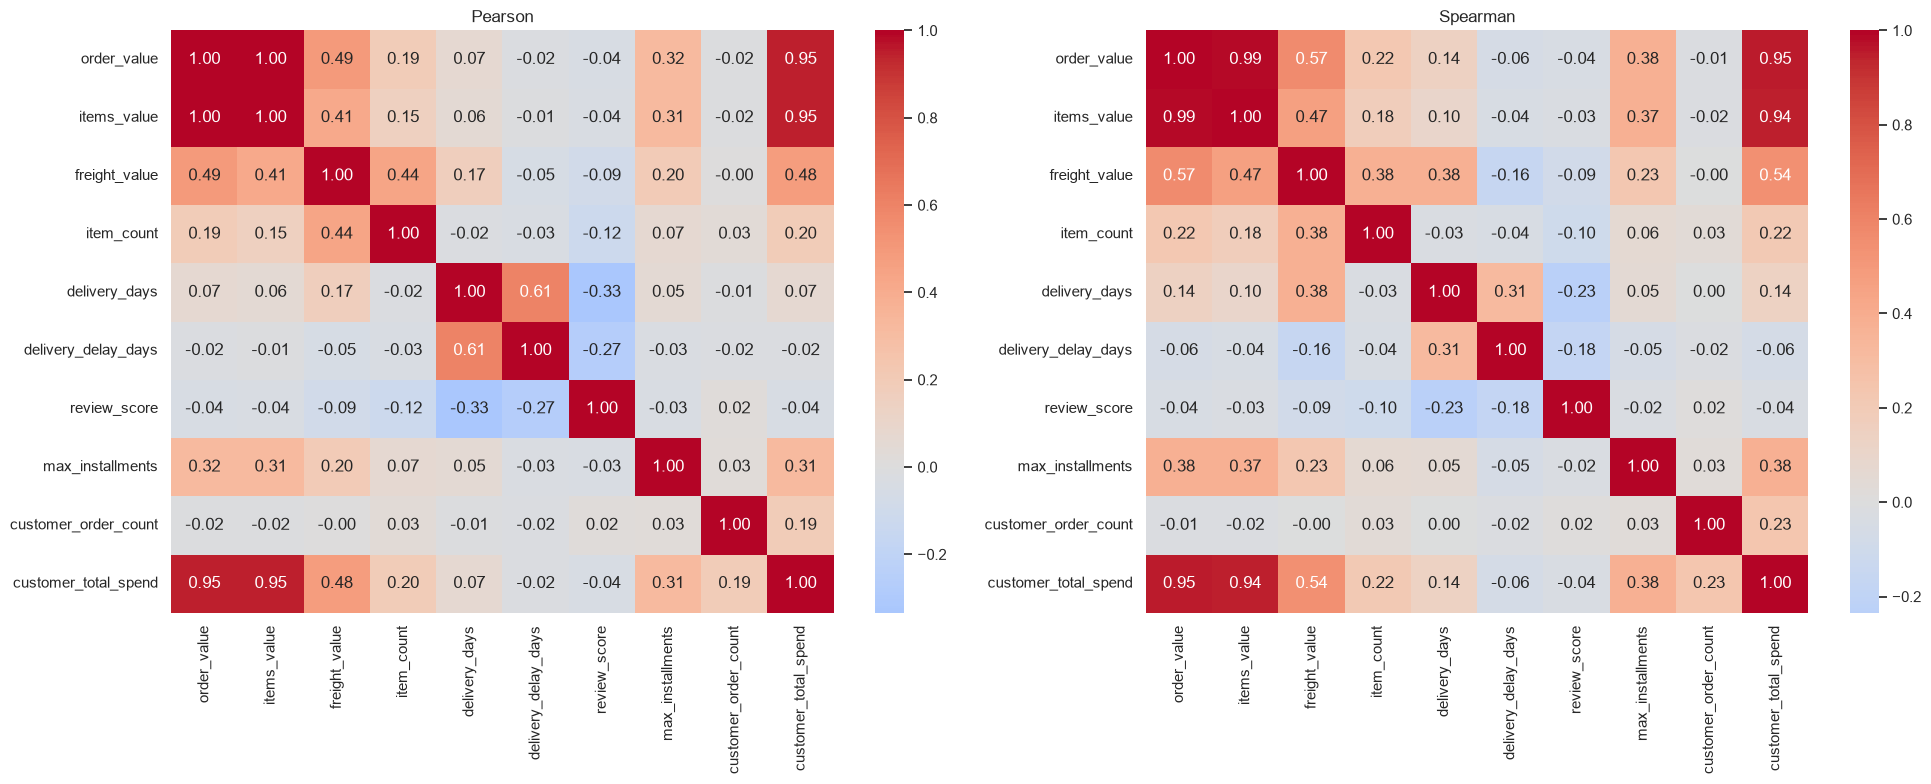

In [30]:
# 8.5 Correlation analysis
corr_cols = ["order_value", "items_value", "freight_value", "item_count", "delivery_days",
             "delivery_delay_days", "review_score", "max_installments",
             "customer_order_count", "customer_total_spend"]
cdata = orders_valid[corr_cols]

pearson  = cdata.corr(method="pearson")
spearman = cdata.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(pearson,  annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0]); axes[0].set_title("Pearson")
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1]); axes[1].set_title("Spearman")
plt.tight_layout()
plt.show()

In [31]:
# Strongest correlated pairs
mask = np.triu(np.ones(pearson.shape), k=1).astype(bool)
pairs = pearson.where(mask).stack().sort_values(key=abs, ascending=False).head(10)
pairs.rename("pearson_r")

order_value    items_value             0.995940
               customer_total_spend    0.952591
items_value    customer_total_spend    0.948076
delivery_days  delivery_delay_days     0.607346
order_value    freight_value           0.492224
freight_value  customer_total_spend    0.475144
               item_count              0.437246
items_value    freight_value           0.411865
delivery_days  review_score           -0.334046
order_value    max_installments        0.320473
Name: pearson_r, dtype: float64

In [ ]:
# 8.6 Distribution analysis

In [32]:
dist_cols = ["order_value", "freight_value", "delivery_days", "delivery_delay_days", "review_score"]
pd.DataFrame({"skew": orders_valid[dist_cols].skew(),
              "kurtosis": orders_valid[dist_cols].kurt()})

,skew,kurtosis
order_value,9.259916,244.098734
freight_value,12.098669,568.467740
delivery_days,3.833377,39.316922
delivery_delay_days,2.011004,28.039331
review_score,-1.414718,0.693559


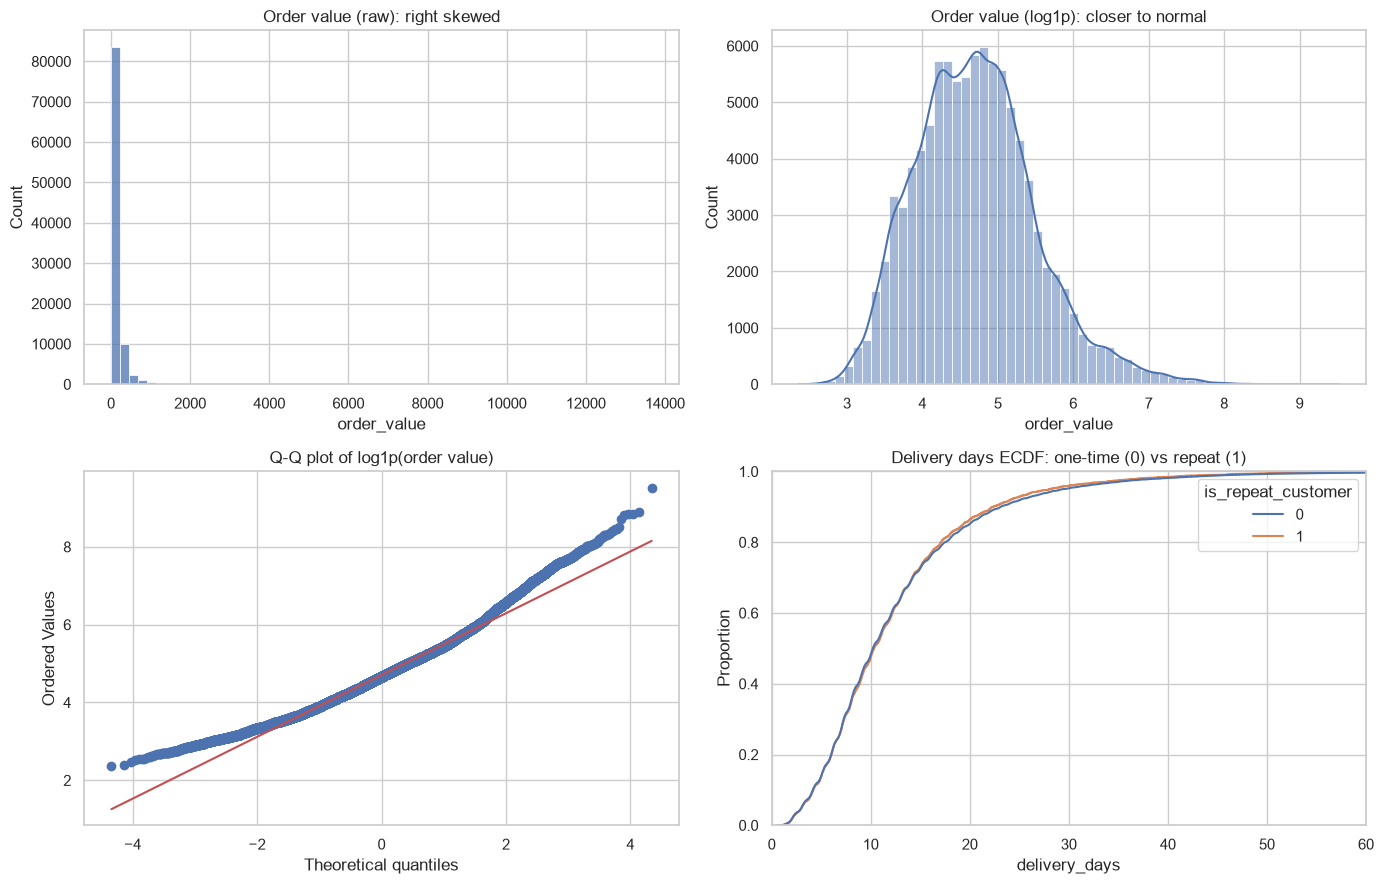

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(orders_valid["order_value"], bins=60, ax=axes[0, 0])
axes[0, 0].set_title("Order value (raw): right skewed")

sns.histplot(np.log1p(orders_valid["order_value"]), bins=60, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Order value (log1p): closer to normal")

stats.probplot(np.log1p(orders_valid["order_value"]), dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q plot of log1p(order value)")

sns.ecdfplot(data=delivered, x="delivery_days", hue="is_repeat_customer", ax=axes[1, 1])
axes[1, 1].set_title("Delivery days ECDF: one-time (0) vs repeat (1)")
axes[1, 1].set_xlim(0, 60)

plt.tight_layout()
plt.show()

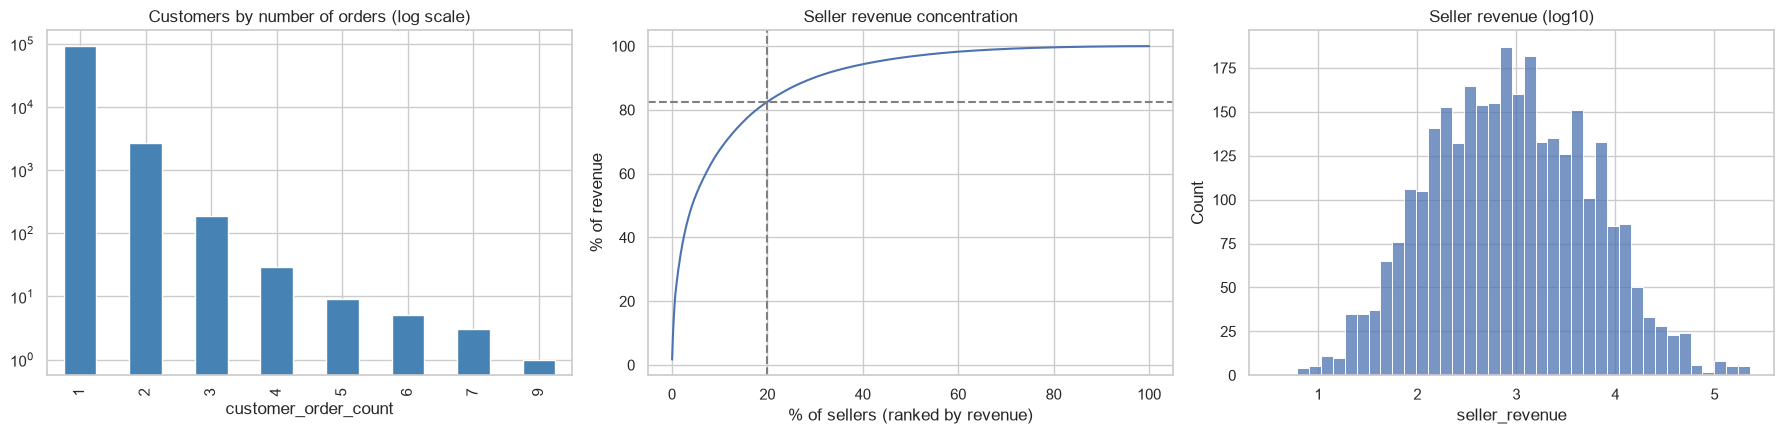

Top 10% of sellers earn 67.5% of revenue
Top 20% of sellers earn 82.6% of revenue


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

customer_features["customer_order_count"].value_counts().sort_index().head(8).plot(
    kind="bar", ax=axes[0], color="steelblue", logy=True)
axes[0].set_title("Customers by number of orders (log scale)")

rev = seller_features["seller_revenue"].sort_values(ascending=False).reset_index(drop=True)
cum_share = rev.cumsum() / rev.sum()
x = (np.arange(1, len(rev) + 1) / len(rev)) * 100
axes[1].plot(x, cum_share * 100)
axes[1].axvline(20, color="grey", ls="--"); axes[1].axhline(cum_share.iloc[int(len(rev) * 0.2)] * 100, color="grey", ls="--")
axes[1].set_xlabel("% of sellers (ranked by revenue)"); axes[1].set_ylabel("% of revenue")
axes[1].set_title("Seller revenue concentration")

sns.histplot(np.log10(seller_features["seller_revenue"].clip(lower=1)), bins=40, ax=axes[2])
axes[2].set_title("Seller revenue (log10)")
plt.tight_layout()
plt.show()

print("Top 10% of sellers earn {:.1f}% of revenue".format(cum_share.iloc[int(len(rev) * 0.10)] * 100))
print("Top 20% of sellers earn {:.1f}% of revenue".format(cum_share.iloc[int(len(rev) * 0.20)] * 100))

In [ ]:
# 8.7 Key findings
"""
the revenue and order trend over time
the effect of late delivery on review scores
the share of repeat customers
how much revenue comes from the top sellers
the strongest correlations
"""